In [ ]:
Data Collection.
    o	Collect the dataset or Create the dataset
?	Data Preprocessing.
    o	Import the Libraries.
    o	Importing the dataset.
    o	Checking for Null Values.
    o	Data Visualization.
    o	Outlier Detection
    o	Splitting Dependent and Independent variables
    o-	Encoding
    o	Feature Scaling.
    o	Splitting Data into Train and Test.
?	Model Building
    o	Import the model building Libraries
    o	Initializing the model
    o	Training and testing the model
    o	Evaluation of Model
    o	Save the Model

## ?	Data Preprocessing.
    o	Import the Libraries.
    o	Importing the dataset.
    o	Checking for Null Values.
    o	Data Visualization.
    o	Outlier Detection
    o	Splitting Dependent and Independent variables
    o-	Encoding
    o	Feature Scaling.
    o	Splitting Data into Train and Test.

In [ ]:
#Import the Libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#Importing the dataset.
df=pd.read_csv("Social_Network_Ads.csv")

In [ ]:
df.head()

In [ ]:
df.shape

In [ ]:
df.Purchased.value_counts()

In [ ]:
df.info()

In [ ]:
df.describe()

In [ ]:
#Checking for Null Values.
df.isnull().any()

In [ ]:
df.isnull().sum()

In [ ]:
#Data Visualization.
sns.distplot(df["Age"])

In [ ]:
df.corr()

In [ ]:
df.head()

In [ ]:
sns.heatmap(df.corr(),annot=True)

In [ ]:
sns.boxplot(df.EstimatedSalary)
#sns.boxplot(df["EstimatedSalary"])

In [ ]:
sns.boxplot(df.Age)

In [ ]:
df.head()

In [ ]:
#Splitting Dependent and Independent variables
x=df.iloc[:,1:4]
x.head()

In [ ]:
y=df.Purchased
y.head()

In [ ]:
#label encoding
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
x.Gender=le.fit_transform(x.Gender)
x.head()

In [ ]:
#feature scaling
from sklearn.preprocessing import MinMaxScaler
ms=MinMaxScaler()
x_scaled=pd.DataFrame(ms.fit_transform(x),columns=x.columns)

In [ ]:
x_scaled


In [ ]:
#Splitting Data into Train and Test.
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x_scaled,y,test_size=0.2,random_state=0)

In [ ]:
x_train.shape,x_test.shape,y_train.shape,y_test.shape

In [ ]:
x_train.head()

# ?	Model Building
    o	Import the model building Libraries
    o	Initializing the model
    o	Training and testing the model
    o	Evaluation of Model
    o	Save the Model

In [ ]:
from sklearn.svm import SVC
model=SVC(probability=True)

In [ ]:
rand_list={"C":[2,3,5,6,7,8,10],
           "gamma":[0.1,0.2,0.5,0.4,0.8]}

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
rand_search=RandomizedSearchCV(model,param_distributions=rand_list,n_iter=20,cv=5)

In [ ]:
rand_search.fit(x_train,y_train)

In [ ]:
pred=rand_search.predict(x_test)

In [ ]:
pred

In [ ]:
y_test

In [ ]:
df

In [ ]:
rand_search.predict(ms.transform([[1,19,19000]]))

# Evaluation of classification model

In [ ]:
#Accuracy score
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,roc_auc_score,roc_curve

In [ ]:
accuracy_score(y_test,pred)

In [ ]:
confusion_matrix(y_test,pred)

In [ ]:
pd.crosstab(y_test,pred)

In [ ]:
           predicted no     predicted yes
Actual No      58=TN                 0=FP
Actual yes     6=FN                  16=TP



In [ ]:
(58+16)/80 #accuracy

In [ ]:
print(classification_report(y_test,pred))

In [ ]:
# precision
# of all positive predictions how many are really positive
#when it predicts yes,how often it is correct

# precision = TP/(TP+FP)
16/0+16


In [ ]:
# Recall
# of all real positive cases how many are predicted positive
#when it is acutally is yes ,how often does it predict yes

# Recall = TP/(FN+TP)
16/16+6

In [ ]:
# F1 score

# 2*precision*Recall/(Precision+Recall)


### Roc-AUC curve

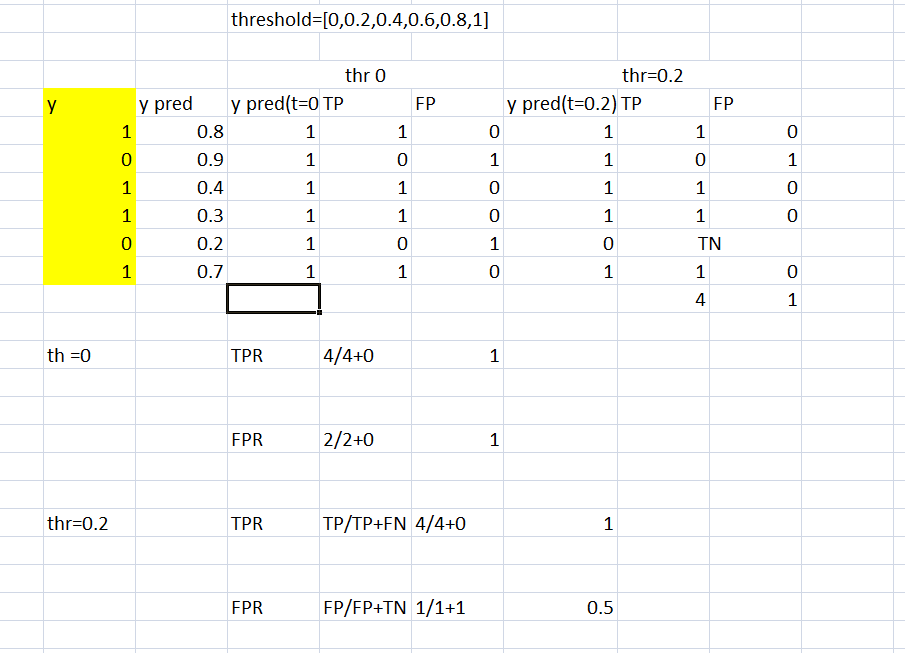

In [ ]:
probability=rand_search.predict_proba(x_test)[:,1]

In [ ]:
probability

In [ ]:
# roc_curve
fpr,tpr,threshsholds = roc_curve(y_test,probability)

In [ ]:
plt.plot(fpr,tpr)
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC CURVE')
plt.show()